# Weather Category Prediction Using Machine Learning
**Author:** Harpreet Singh

This notebook trains machine learning models to **classify the weather category of a day** (`sun`, `rain`, `fog`, `drizzle`, `snow`) from that day's measurements: temperatures, wind and month.

> **Note:** this is a *classification* task on same-day measurements, not a weather *forecast*. The data is the Seattle daily weather dataset (2012–2015, 1,461 rows) from [vega-datasets](https://github.com/vega/vega-datasets).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load data and feature engineering
The notebook reads `data/seattle_weather.csv` if it exists (local or cloned repo). Otherwise it downloads the same file from vega-datasets, so it also runs in a fresh Google Colab session.

In [2]:
LOCAL_PATH = "data/seattle_weather.csv"
URL = "https://raw.githubusercontent.com/vega/vega-datasets/main/data/seattle-weather.csv"

try:
    df = pd.read_csv(LOCAL_PATH)
except FileNotFoundError:
    df = pd.read_csv(URL)

df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month

print(f"Rows: {len(df)}  |  Missing values: {int(df.isna().sum().sum())}")
print("\nClass distribution:")
print(df["weather"].value_counts())
majority = df["weather"].value_counts(normalize=True).iloc[0]
print(f"\nBaseline: always predicting 'rain' would give {majority:.1%} accuracy.")
df.head()

Rows: 1461  |  Missing values: 0

Class distribution:
weather
rain       641
sun        640
fog        101
drizzle     53
snow        26
Name: count, dtype: int64

Baseline: always predicting 'rain' would give 43.9% accuracy.


        date  precipitation  temp_max  temp_min  wind  weather  month
0 2012-01-01            0.0      12.8       5.0   4.7  drizzle      1
1 2012-01-02           10.9      10.6       2.8   4.5     rain      1
2 2012-01-03            0.8      11.7       7.2   2.3     rain      1
3 2012-01-04           20.3      12.2       5.6   4.7     rain      1
4 2012-01-05            1.3       8.9       2.8   6.1     rain      1

## 2. Helper functions
A single split is noisy here because the test set holds only about 5 snow days. So each scenario is evaluated twice: on a stratified 80/20 split (below) and with 5-fold cross-validation (section 5).

In [3]:
FEATURES_BASE = ["temp_max", "temp_min", "wind", "month"]
FEATURES_PRECIP = ["precipitation"] + FEATURES_BASE
y = df["weather"]
LABELS = sorted(y.unique())


def evaluate_on_split(name, model, features, cmap="Blues"):
    """Train on a stratified 80/20 split, then print metrics and plot the confusion matrix."""
    X_train, X_test, y_train, y_test = train_test_split(
        df[features], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    macro_f1 = f1_score(y_test, preds, average="macro", zero_division=0)
    print(f"{name}\nAccuracy: {acc:.3f}   Macro F1: {macro_f1:.3f}\n")
    print(classification_report(y_test, preds, zero_division=0))

    plt.figure(figsize=(6, 4.5))
    sns.heatmap(confusion_matrix(y_test, preds, labels=LABELS), annot=True, fmt="d", cmap=cmap,
                xticklabels=LABELS, yticklabels=LABELS)
    plt.title(f"{name}\nConfusion Matrix (test split)")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.tight_layout()
    plt.show()

## 3. Scenario 1: without precipitation
Features: `temp_max`, `temp_min`, `wind`, `month`.

### Logistic Regression (baseline)

Logistic Regression (no precipitation)
Accuracy: 0.676   Macro F1: 0.288

              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00        11
         fog       0.00      0.00      0.00        20
        rain       0.70      0.80      0.74       129
        snow       0.00      0.00      0.00         5
         sun       0.66      0.74      0.70       128

    accuracy                           0.68       293
   macro avg       0.27      0.31      0.29       293
weighted avg       0.59      0.68      0.63       293



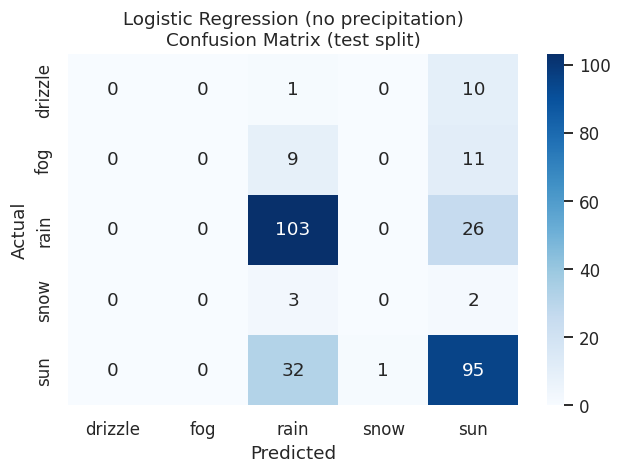

In [4]:
evaluate_on_split("Logistic Regression (no precipitation)",
                  LogisticRegression(max_iter=1000), FEATURES_BASE, cmap="Blues")

### Random Forest

Random Forest (no precipitation)
Accuracy: 0.662   Macro F1: 0.407

              precision    recall  f1-score   support

     drizzle       0.25      0.09      0.13        11
         fog       0.40      0.10      0.16        20
        rain       0.70      0.78      0.74       129
        snow       1.00      0.20      0.33         5
         sun       0.64      0.70      0.67       128

    accuracy                           0.66       293
   macro avg       0.60      0.37      0.41       293
weighted avg       0.64      0.66      0.64       293



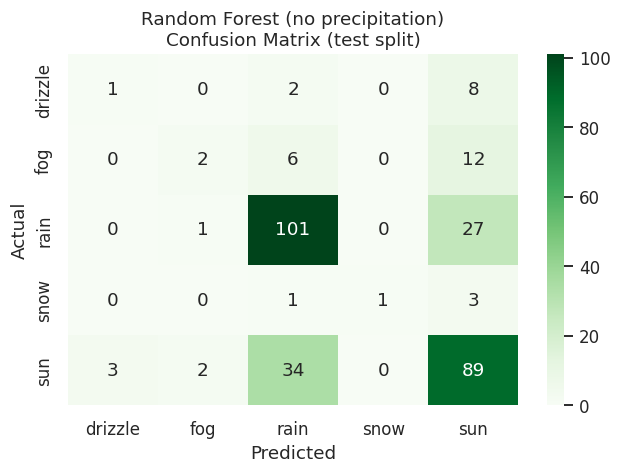

In [5]:
evaluate_on_split("Random Forest (no precipitation)",
                  RandomForestClassifier(random_state=RANDOM_STATE), FEATURES_BASE, cmap="Greens")

## 4. Scenario 2: with precipitation
In this dataset precipitation is exactly 0 on every `sun`, `fog` and `drizzle` day, and above 0 on all `snow` days and 93% of `rain` days, so it is very closely tied to the label. Accuracy goes up a lot, but the model is partly reading the answer from a variable that describes the same thing.

Random Forest (with precipitation)
Accuracy: 0.840   Macro F1: 0.565

              precision    recall  f1-score   support

     drizzle       0.25      0.09      0.13        11
         fog       0.50      0.25      0.33        20
        rain       0.97      0.91      0.94       129
        snow       1.00      0.40      0.57         5
         sun       0.78      0.95      0.85       128

    accuracy                           0.84       293
   macro avg       0.70      0.52      0.57       293
weighted avg       0.83      0.84      0.82       293



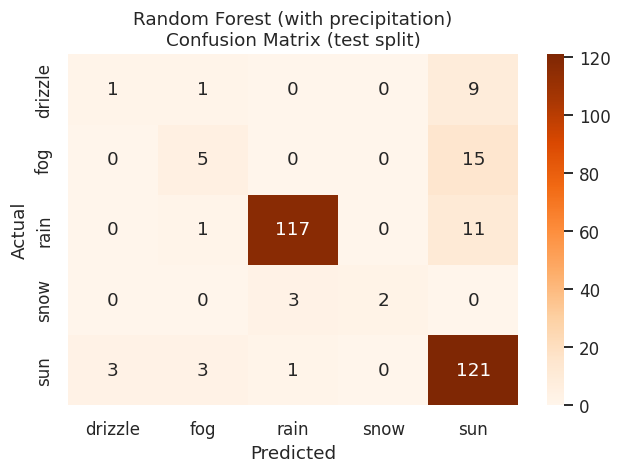

In [6]:
evaluate_on_split("Random Forest (with precipitation)",
                  RandomForestClassifier(random_state=RANDOM_STATE), FEATURES_PRECIP, cmap="Oranges")

## 5. Fair comparison with 5-fold cross-validation
Every row is used for testing exactly once, which gives more stable numbers than a single split. `balanced` means `class_weight="balanced"`, which gives rare classes more weight during training.

In [7]:
scenarios = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), FEATURES_BASE),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), FEATURES_BASE),
    "Random Forest (balanced)": (RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"), FEATURES_BASE),
    "Random Forest + precipitation": (RandomForestClassifier(random_state=RANDOM_STATE), FEATURES_PRECIP),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows, recalls = [], {}
for name, (model, feats) in scenarios.items():
    scores = cross_validate(model, df[feats], y, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({
        "Model": name,
        "Features": "with precipitation" if "precipitation" in feats else "without precipitation",
        "Accuracy": f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        "Macro F1": f"{scores['test_f1_macro'].mean():.3f} ± {scores['test_f1_macro'].std():.3f}",
    })
    oof = cross_val_predict(model, df[feats], y, cv=cv)
    recalls[name] = recall_score(y, oof, labels=LABELS, average=None, zero_division=0)

results = pd.DataFrame(rows)
print(results.to_string(index=False))
print(f"\nAlways predicting 'rain' (baseline): accuracy {majority:.3f}")

recall_table = pd.DataFrame(recalls, index=LABELS).T.round(2)
print("\nRecall per class (out-of-fold predictions):")
print(recall_table.to_string())

                        Model              Features      Accuracy      Macro F1
          Logistic Regression without precipitation 0.692 ± 0.013 0.322 ± 0.032
                Random Forest without precipitation 0.691 ± 0.009 0.430 ± 0.014
     Random Forest (balanced) without precipitation 0.678 ± 0.015 0.393 ± 0.026
Random Forest + precipitation    with precipitation 0.852 ± 0.012 0.552 ± 0.049

Always predicting 'rain' (baseline): accuracy 0.439

Recall per class (out-of-fold predictions):
                               drizzle   fog  rain  snow   sun
Logistic Regression               0.00  0.00  0.81  0.12  0.76
Random Forest                     0.09  0.12  0.78  0.27  0.76
Random Forest (balanced)          0.09  0.08  0.78  0.19  0.74
Random Forest + precipitation     0.08  0.16  0.93  0.54  0.97


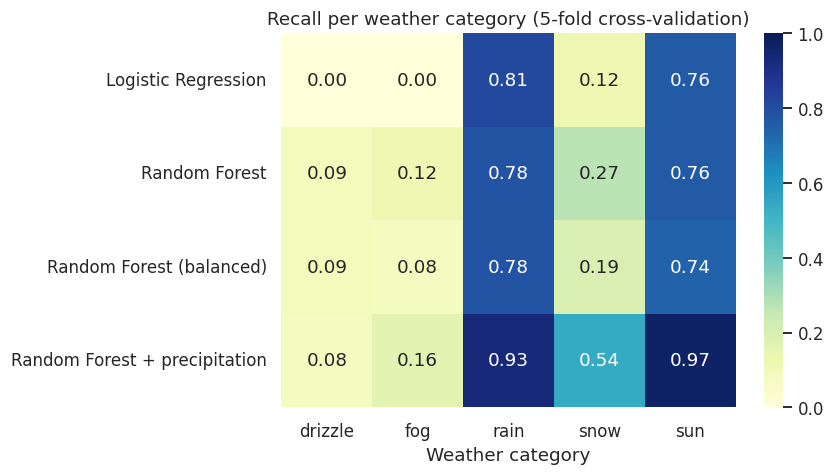

In [8]:
plt.figure(figsize=(8, 4.5))
sns.heatmap(recall_table, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Recall per weather category (5-fold cross-validation)")
plt.xlabel("Weather category")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Things I tried
Three extra ideas, evaluated with the same 5-fold cross-validation:

1. **Yesterday's weather** (`prev_` features) added to the model.
2. **Gradient Boosting** (`HistGradientBoostingClassifier`) instead of Random Forest.
3. **A real forecast:** predict *tomorrow's* category from today's measurements, compared with a simple "tomorrow will be the same as today" rule.

The first day (no yesterday) and the last day (no tomorrow) are dropped where needed, so row counts differ by one.

In [9]:
d = df.sort_values("date").reset_index(drop=True).copy()
for col in ["temp_max", "temp_min", "wind", "precipitation"]:
    d[f"prev_{col}"] = d[col].shift(1)
d["prev_weather"] = d["weather"].shift(1).map({w: i for i, w in enumerate(LABELS)})
d["tomorrow"] = d["weather"].shift(-1)

PREV = ["prev_temp_max", "prev_temp_min", "prev_wind", "prev_precipitation", "prev_weather"]
TODAY_WITH_PRECIP = ["precipitation"] + FEATURES_BASE


def cv_scores(data, features, target, model):
    data = data.dropna(subset=features + [target])
    s = cross_validate(model, data[features], data[target], cv=cv, scoring=["accuracy", "f1_macro"])
    return s["test_accuracy"].mean(), s["test_f1_macro"].mean()


def rf():
    return RandomForestClassifier(random_state=RANDOM_STATE)


experiments = [
    ("Today's weather, Random Forest (reference)", d, FEATURES_BASE, "weather", rf()),
    ("+ yesterday's weather", d, FEATURES_BASE + PREV, "weather", rf()),
    ("Gradient Boosting instead of Random Forest", d, FEATURES_BASE, "weather",
     HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ("Forecast TOMORROW from today (Random Forest)", d, TODAY_WITH_PRECIP, "tomorrow", rf()),
]
rows = []
for name, data, feats, target, model in experiments:
    acc, f1 = cv_scores(data, feats, target, model)
    rows.append({"Experiment": name, "Accuracy": round(acc, 3), "Macro F1": round(f1, 3)})

same_as_today = (d["weather"].shift(-1) == d["weather"])[:-1].mean()
always_rain = (d["tomorrow"].dropna() == "rain").mean()
rows.append({"Experiment": "Rule: tomorrow = today (no model)", "Accuracy": round(same_as_today, 3), "Macro F1": np.nan})
rows.append({"Experiment": "Rule: tomorrow = rain (no model)", "Accuracy": round(always_rain, 3), "Macro F1": np.nan})
print(pd.DataFrame(rows).to_string(index=False))

                                  Experiment  Accuracy  Macro F1
  Today's weather, Random Forest (reference)     0.691     0.430
                       + yesterday's weather     0.702     0.461
  Gradient Boosting instead of Random Forest     0.663     0.405
Forecast TOMORROW from today (Random Forest)     0.627     0.362
           Rule: tomorrow = today (no model)     0.632       NaN
            Rule: tomorrow = rain (no model)     0.439       NaN


## 7. Which features matter?
Random Forest feature importances, fitted on all data. These importances can favour continuous features, so they show a rough ranking and not an exact contribution.

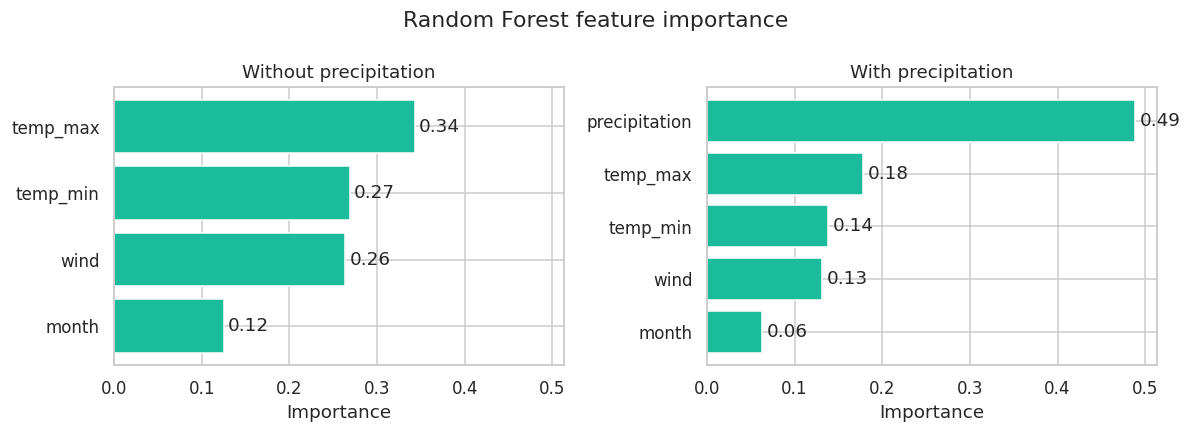

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, (title, feats) in zip(axes, [("Without precipitation", FEATURES_BASE), ("With precipitation", FEATURES_PRECIP)]):
    model = RandomForestClassifier(random_state=RANDOM_STATE).fit(df[feats], y)
    imp = pd.Series(model.feature_importances_, index=feats).sort_values()
    ax.barh(imp.index, imp.values, color="#1abc9c")
    ax.set_title(title)
    ax.set_xlabel("Importance")
    for i, v in enumerate(imp.values):
        ax.text(v + 0.005, i, f"{v:.2f}", va="center")
plt.suptitle("Random Forest feature importance")
plt.tight_layout()
plt.show()

## 8. Conclusions
- **Baseline:** always guessing `rain` gives 43.9% accuracy. Every model beats that.
- **Without precipitation** both models reach about 69% accuracy. Random Forest is *not* more accurate than Logistic Regression, but it has a higher macro F1 (about 0.43 vs 0.32) because it sometimes recognises rare classes.
- **With precipitation** Random Forest reaches about 85% accuracy and macro F1 of about 0.55. The jump is real but partly leakage-like, because precipitation is almost the definition of rain and snow.
- **Class imbalance matters.** `rain` and `sun` are recognised reasonably well (recall about 0.8); `fog`, `drizzle` and `snow` are rare (101, 53 and 26 days), and `drizzle` is almost never predicted correctly. Overall accuracy hides this, so macro F1 and per-class recall should always be reported.
- `class_weight="balanced"` did not help in cross-validation.
- **Extra experiments:** adding yesterday's weather helps a little (macro F1 about 0.43 to 0.46), Gradient Boosting is no better than Random Forest on this small dataset, and forecasting *tomorrow* is no better than simply repeating today's category.
- **Feature importance:** without precipitation the temperatures and wind carry most of the signal; with it, `precipitation` alone accounts for about half of the importance (0.49).
- **Limits:** one city, four years, and the `weather` label is not always consistent with the precipitation measurement.

**Ideas for next steps:** use more years of data, add more weather variables (pressure, humidity), and tune hyperparameters with nested cross-validation.